# Лабораторная работа 6. Основы использования библиотеки PyTorch

In [1]:
import torch
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)
print("CUDA доступна:", torch.cuda.is_available())

PyTorch: 2.10.0+cpu
CUDA доступна: False


## Учебные задачи

### Задача 1. Простейшие операции над тензорами

In [33]:
a = torch.rand(3, 4)
b = torch.rand(12)
c = b.view(2, 2, 3)

print("a:\n", a)
print("b:\n", b)
print("c:\n", c)
print("первый столбец a:", a[:, 0])

a:
 tensor([[0.0584, 0.1392, 0.3044, 0.7029],
        [0.8779, 0.7935, 0.4262, 0.1387],
        [0.5020, 0.3115, 0.4853, 0.6815]])
b:
 tensor([0.2773, 0.1111, 0.6662, 0.4732, 0.8954, 0.3050, 0.1152, 0.2860, 0.5685,
        0.0722, 0.5523, 0.8730])
c:
 tensor([[[0.2773, 0.1111, 0.6662],
         [0.4732, 0.8954, 0.3050]],

        [[0.1152, 0.2860, 0.5685],
         [0.0722, 0.5523, 0.8730]]])
первый столбец a: tensor([0.0584, 0.8779, 0.5020])


### Задача 2. Арифметические операции над тензорами

In [34]:
a = torch.rand(5, 2)
b = torch.rand(1, 10)
c = b.view(5, 2)

print("a + c:\n", a + c)
print("a - c:\n", a - c)
print("a * c:\n", a * c)
print("a / c:\n", a / c)
print("a ** c:\n", a ** c)
print("a % c:\n", a % c)
print("a // c:\n", a // c)

a + c:
 tensor([[0.7794, 1.2701],
        [0.5155, 1.3390],
        [1.7785, 0.2440],
        [1.4292, 1.2085],
        [1.3225, 0.7828]])
a - c:
 tensor([[ 0.2094,  0.0383],
        [ 0.4329,  0.6420],
        [ 0.0252, -0.0462],
        [ 0.1885, -0.3460],
        [ 0.6479,  0.3388]])
a * c:
 tensor([[0.1409, 0.4029],
        [0.0196, 0.3452],
        [0.7906, 0.0144],
        [0.5018, 0.3352],
        [0.3323, 0.1245]])
a / c:
 tensor([[ 1.7346,  1.0622],
        [11.4796,  2.8421],
        [ 1.0287,  0.6815],
        [ 1.3039,  0.5548],
        [ 2.9211,  2.5262]])
a ** c:
 tensor([[0.8181, 0.7700],
        [0.9696, 0.9967],
        [0.9134, 0.7148],
        [0.8767, 0.5201],
        [0.9950, 0.8795]])
a % c:
 tensor([[0.2094, 0.0383],
        [0.0198, 0.2935],
        [0.0252, 0.0989],
        [0.1885, 0.4312],
        [0.3107, 0.1168]])
a // c:
 tensor([[ 1.,  1.],
        [11.,  2.],
        [ 1.,  0.],
        [ 1.,  0.],
        [ 2.,  2.]])


### Задача 3. Функции сравнения, агрегации

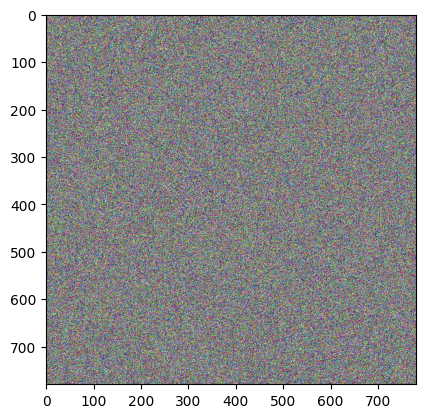

среднее по 1-й оси: torch.Size([100, 780, 3])
среднее по 4-й оси: torch.Size([100, 780, 780])


In [35]:
a = torch.rand(100, 780, 780, 3)

plt.imshow(a[0])
plt.show()

mean_axis1 = a.mean(dim=1)
mean_axis4 = a.mean(dim=3)
print("среднее по 1-й оси:", mean_axis1.shape)
print("среднее по 4-й оси:", mean_axis4.shape)

### Задача 4. Реализация функции прямого распространения

In [36]:
def forward_pass_np(X, w):
    z = X @ w[:-1] + w[-1]
    return 1 / (1 + np.exp(-z))


def forward_pass(X, w):
    z = X @ w[:-1] + w[-1]
    return torch.sigmoid(z)


X = torch.rand(5, 3)
w = torch.rand(4)

print(forward_pass_np(X.numpy(), w.numpy()))
print(forward_pass(X, w))

[0.67684317 0.8160165  0.82129365 0.73219585 0.6508213 ]
tensor([0.6768, 0.8160, 0.8213, 0.7322, 0.6508])


### Задача 5. Тензоры на устройстве и градиенты

In [37]:
a = torch.FloatTensor(2, 3, 4).uniform_()
b = torch.FloatTensor(1, 8, 3).uniform_()

device = "cuda" if torch.cuda.is_available() else "cpu"
a_dev = a.to(device)
b_dev = b.to(device)

# формы (2, 3, 4) и (1, 8, 3) несовместимы для поэлементных операций,
# поэтому b приводится к форме a
c_dev = b_dev.view(a_dev.shape)

print("сумма:\n", a_dev + c_dev)
print("разность:\n", a_dev - c_dev)

сумма:
 tensor([[[1.7691, 1.4721, 1.4749, 0.5066],
         [0.7138, 1.2750, 1.3218, 1.0382],
         [1.7143, 1.2129, 1.2363, 1.8076]],

        [[1.3136, 1.1444, 1.3076, 1.8291],
         [0.6586, 0.9658, 1.2035, 0.2930],
         [0.6459, 0.5498, 0.7666, 0.9726]]])
разность:
 tensor([[[-0.1321, -0.4034,  0.0685, -0.2675],
         [-0.2279, -0.0172,  0.5498,  0.6381],
         [-0.2459, -0.1556, -0.5790,  0.1620]],

        [[-0.5800,  0.0143, -0.2741,  0.0537],
         [-0.0206, -0.6675,  0.0601, -0.0274],
         [-0.3077,  0.3868, -0.3311, -0.2347]]])


In [38]:
c = c_dev.cpu()
a = a_dev.cpu()

c = Variable(c, requires_grad=True)
a = Variable(a, requires_grad=True)

L = torch.mean((c - a) ** 2)
L.backward()
print("градиент L по c:\n", c.grad)

c_tensor = c.data.type(torch.FloatTensor)
print(type(c_tensor))

градиент L по c:
 tensor([[[ 0.0110,  0.0336, -0.0057,  0.0223],
         [ 0.0190,  0.0014, -0.0458, -0.0532],
         [ 0.0205,  0.0130,  0.0483, -0.0135]],

        [[ 0.0483, -0.0012,  0.0228, -0.0045],
         [ 0.0017,  0.0556, -0.0050,  0.0023],
         [ 0.0256, -0.0322,  0.0276,  0.0196]]])
<class 'torch.Tensor'>


# Индивидуальное задание. Классификация авторства кода

In [1]:
import pandas as pd

DATA_PATH = "datasets/Code_Dataset/HumanVsAI_CodeDataset.csv"
df = pd.read_csv(DATA_PATH)

print("Размер набора:", df.shape)
print(df["Generated"].value_counts())
print(df["Language"].value_counts())
df.head(3)

Размер набора: (10000, 5)
Generated
Human    5000
AI       5000
Name: count, dtype: int64
Language
Java      2945
Python    2678
C++       2640
C         1737
Name: count, dtype: int64


,problem_id,Sample_Code,Generated,Language,Source
0,Prob3509,\n/* ITP1_2_D */\n\nimport Java.io.*;\nimport ...,Human,Java,CodeNet
1,Prob292,import Java.util.Scanner;\n\npublic class Main...,Human,Java,CodeNet
2,Prob4407,from datetime import datetime\n\ndef get_time_...,AI,Python,ChatGPT-4


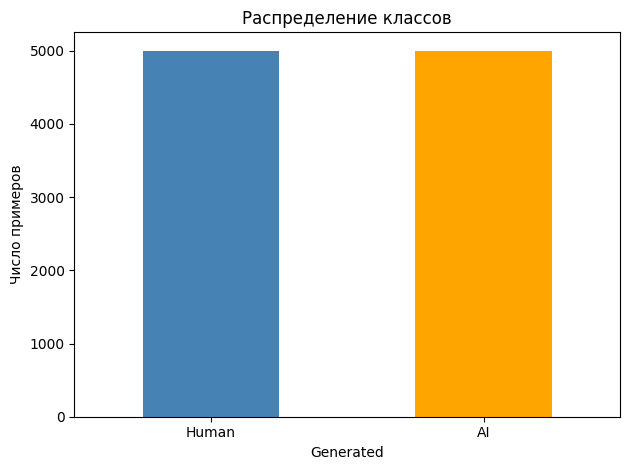

In [40]:
counts = df["Generated"].value_counts()
counts.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Распределение классов")
plt.ylabel("Число примеров")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/fig01_classes.png", dpi=150, bbox_inches="tight")
plt.show()

In [41]:
import re

KEYWORDS = {"if", "else", "for", "while", "return", "def", "class",
            "public", "static", "import", "try", "void", "int", "print"}


def extract_features(code):
    code = str(code)
    n = max(len(code), 1)
    lines = code.split("\n")
    n_lines = max(len(lines), 1)

    comments = re.findall(r"(?s)(//.*?$|/\*.*?\*/|#.*?$|\'\'\'.*?\'\'\'|\"\"\".*?\"\"\")",
                          code, flags=re.MULTILINE)
    words = re.findall(r"\b[a-zA-Z_][a-zA-Z0-9_]*\b", code)
    n_words = max(len(words), 1)

    nonempty = [line for line in lines if line.strip()]
    indents = [len(line) - len(line.lstrip(" ")) for line in nonempty] or [0]
    tabs = sum(1 for line in lines if line.startswith("\t"))

    return {
        "length": len(code),
        "n_lines": len(lines),
        "avg_line_len": len(code) / n_lines,
        "max_line_len": max((len(line) for line in lines), default=0),
        "comment_ratio": sum(len(c) for c in comments) / n,
        "avg_ident_len": sum(len(w) for w in words) / n_words,
        "keyword_density": sum(1 for w in words if w in KEYWORDS) / n_words,
        "bracket_density": sum(code.count(ch) for ch in "{}()[]") / n,
        "operator_density": sum(code.count(op) for op in
                                ["+", "-", "*", "/", "%", "==", "!=", "<", ">"]) / n,
        "digit_ratio": sum(ch.isdigit() for ch in code) / n,
        "space_ratio": code.count(" ") / n,
        "tab_ratio": tabs / n_lines,
        "unique_word_ratio": len(set(words)) / n_words,
        "avg_indent": sum(indents) / len(indents),
    }


features = pd.DataFrame([extract_features(c) for c in df["Sample_Code"]])
print(features.shape)
features.head()

(10000, 14)


,length,n_lines,avg_line_len,max_line_len,comment_ratio,avg_ident_len,keyword_density,bracket_density,operator_density,digit_ratio,space_ratio,tab_ratio,unique_word_ratio,avg_indent
0,473,25,18.920000,78,0.029598,3.742424,0.212121,0.097252,0.029598,0.008457,0.198732,0.000000,0.515152,1.555556
1,444,30,14.800000,41,0.000000,3.721311,0.262295,0.103604,0.029279,0.029279,0.128378,0.666667,0.524590,0.173913
2,380,15,25.333333,54,0.039474,5.444444,0.111111,0.057895,0.026316,0.021053,0.123684,0.000000,0.666667,1.692308
3,396,19,20.842105,41,0.000000,2.000000,0.136986,0.151515,0.037879,0.040404,0.272727,0.000000,0.273973,2.315789
4,1491,88,16.943182,45,0.075788,4.786164,0.144654,0.049631,0.024145,0.014085,0.041583,0.920455,0.320755,0.000000


In [42]:
from sklearn.model_selection import train_test_split

X = features.values.astype("float32")
y = (df["Generated"] == "AI").astype("float32").values

idx_train, idx_test = train_test_split(
    df.index, test_size=0.2, random_state=42, stratify=y)

X_train, X_test = X[idx_train], X[idx_test]
y_train, y_test = y[idx_train], y[idx_test]

mean = X_train.mean(axis=0)
std = X_train.std(axis=0)
std[std == 0] = 1
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (8000, 14)
Тестовая выборка: (2000, 14)


In [43]:
X_train = torch.tensor(X_train)
X_test = torch.tensor(X_test)
y_train = torch.tensor(y_train).view(-1, 1)
y_test = torch.tensor(y_test).view(-1, 1)

In [44]:
torch.manual_seed(42)

w = torch.zeros(X_train.shape[1], 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)

lr = 0.1
losses = []

for epoch in range(500):
    logits = X_train @ w + b
    loss = torch.nn.functional.binary_cross_entropy_with_logits(logits, y_train)
    loss.backward()

    with torch.no_grad():
        w -= lr * w.grad
        b -= lr * b.grad

    w.grad.zero_()
    b.grad.zero_()
    losses.append(loss.item())

print("loss в начале:", round(losses[0], 4))
print("loss в конце:", round(losses[-1], 4))

loss в начале: 0.6931
loss в конце: 0.221


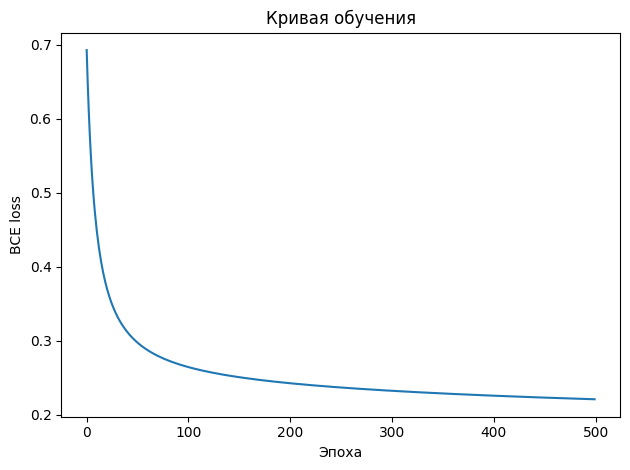

In [45]:
plt.plot(losses)
plt.xlabel("Эпоха")
plt.ylabel("BCE loss")
plt.title("Кривая обучения")
plt.tight_layout()
plt.savefig("figures/fig02_loss.png", dpi=150, bbox_inches="tight")
plt.show()

In [46]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

with torch.no_grad():
    prob = torch.sigmoid(X_test @ w + b).numpy().ravel()

pred = (prob >= 0.5).astype(int)
y_true = y_test.numpy().ravel().astype(int)

print("Accuracy:", round(accuracy_score(y_true, pred), 4))
print("F1:", round(f1_score(y_true, pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_true, prob), 4))
print("Матрица ошибок:\n", confusion_matrix(y_true, pred))

Accuracy: 0.91
F1: 0.9104
ROC-AUC: 0.9674
Матрица ошибок:
 [[906  94]
 [ 86 914]]


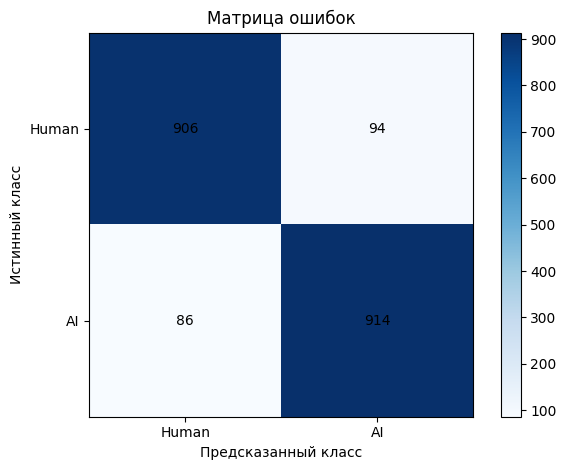

In [47]:
cm = confusion_matrix(y_true, pred)
plt.imshow(cm, cmap="Blues")
plt.title("Матрица ошибок")
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.xticks([0, 1], ["Human", "AI"])
plt.yticks([0, 1], ["Human", "AI"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.savefig("figures/fig03_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

In [48]:
weights = pd.Series(w.detach().numpy().ravel(), index=features.columns)
weights.sort_values(key=abs, ascending=False).round(3)

avg_ident_len        1.720
tab_ratio           -1.258
bracket_density     -0.920
keyword_density     -0.687
avg_line_len         0.633
operator_density    -0.516
n_lines             -0.396
space_ratio          0.357
avg_indent          -0.244
unique_word_ratio   -0.160
digit_ratio          0.146
max_line_len         0.125
length              -0.109
comment_ratio       -0.045
dtype: float32

In [49]:
results = pd.DataFrame({
    "Истина": df.loc[idx_test, "Generated"].values,
    "Предсказание": np.where(pred == 1, "AI", "Human"),
    "P(AI)": prob.round(3),
}, index=idx_test)

print("Доля верных ответов:", round((results["Истина"] == results["Предсказание"]).mean(), 4))
results.head(5)

Доля верных ответов: 0.91


,Истина,Предсказание,P(AI)
5793,Human,Human,0.011
1842,AI,Human,0.274
3250,Human,Human,0.042
9066,AI,AI,0.988
7000,Human,Human,0.194


In [50]:
def predict_origin(code_text):
    row = np.array([[extract_features(code_text)[name] for name in features.columns]],
                   dtype="float32")
    row = (row - mean) / std
    with torch.no_grad():
        p = torch.sigmoid(torch.tensor(row) @ w + b).item()
    return ("AI" if p >= 0.5 else "Human"), p


ai_example = results[(results["Истина"] == "AI") & (results["Предсказание"] == "AI")].index[0]
human_example = results[(results["Истина"] == "Human") & (results["Предсказание"] == "Human")].index[0]

for idx in (human_example, ai_example):
    print("Фрагмент кода:")
    print(df.loc[idx, "Sample_Code"][:250].replace("\n", " "))
    label, p = predict_origin(df.loc[idx, "Sample_Code"])
    print("Истина:", df.loc[idx, "Generated"], "| Предсказание:", label, "| P(AI) =", round(p, 3))
    print()

Фрагмент кода:
import Java.util.Scanner; import Java.util.Arrays; import Java.util.Comparator; import Java.util.Map; import Java.util.HashMap;  public class Main {   String w;   Map<String, Integer> map = new HashMap<>();      public static void main(String args[])
Истина: Human | Предсказание: Human | P(AI) = 0.011

Фрагмент кода:
import Java.security.MessageDigest;  public class SHA256Example {   public static void main(String[] args) throws Exception {     String input = "Hello World";     MessageDigest digest = MessageDigest.getInstance("SHA-256");     byte[] hash = digest.
Истина: AI | Предсказание: AI | P(AI) = 0.988



# Контрольный вопрос

5. Опишите возможности библиотеки PyTorch по вычислению производных. Приведите пример вычисления градиентов для простейшего вычислительного графа.

In [2]:
x = torch.tensor([[1.], [2.], [3.]], requires_grad=True)
w = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.],
                  [7., 8., 9.]], requires_grad=True)
b = torch.tensor([[1.], [1.], [1.]])

y = w @ x + b          # y = Wx + b
L = y.sum()            # L = сумма элементов y
L.backward()

print(x.grad)          # dL/dx = W^T · 1
print(w.grad)          # dL/dw = 1 · x^T

tensor([[12.],
        [15.],
        [18.]])
tensor([[1., 2., 3.],
        [1., 2., 3.],
        [1., 2., 3.]])
